# 02 · Monitoring: what triggered the Model Update
The monitoring plan has six metric families with green/amber/red bands. **All thresholds are internal [JUDGMENT]**; no rule prescribes them. Development is the benchmark.

In [1]:
import sys; sys.path.insert(0, "../src")
from mu_catiii import *
from plots import *
pd.set_option("display.width", 160)
dev, mon, pd_old, lgd, ead = load_inputs()
pooled = pd.concat([dev, mon], ignore_index=True)
term_by_segment = pooled.groupby("segment")["term_months"].max().to_dict()

## 1. Population stability (PSI)
The pool distribution is stable, but the **macro inputs are red**. Cause and effect are different findings: the customers look the same, the environment does not.

In [2]:
display(pd.read_csv(TABLES / '02_psi.csv'))

,metric,object,value,status
0,PSI pool_id (score),portfolio,0.0015,GREEN
1,PSI fico_band,auto_loan,0.0010,GREEN
2,PSI fico_band,personal_loan,0.0013,GREEN
3,PSI fico_band,credit_card,0.0001,GREEN
4,PSI fico_band,heloc,0.0019,GREEN
5,PSI unemployment_rate_regional,macro input,3.3727,RED
6,PSI hpi_change_regional_pct,macro input,1.2808,RED


## 2. Rank ordering
Does the model still sort good from bad? AUC, Gini and KS computed on monitoring outcomes with the production PD as score.

In [3]:
display(pd.read_csv(TABLES / '02_discrimination_monitoring.csv'))

,metric,development,monitoring,change_pct,status
0,AUC-ROC,0.7039,0.7040,0.0001,GREEN
1,Gini,0.4079,0.4079,0.0002,GREEN
2,KS,0.3280,0.3294,0.0040,GREEN


Rank ordering is intact. This is the key to the scope decision: the model **ranks** risk correctly but **levels** are too low. A level problem is a recalibration problem, not a redevelopment problem.

## 3. Levels: actual versus expected
A/E = monitoring default rate ÷ development default rate, by pool, with exact binomial 95% intervals.

,pool_id,n_mon,rate_dev,rate_mon,AE_ratio,AE_ci_low,AE_ci_high,bonferroni_p,status
0,heloc | prime(680-719),436,0.0455,0.0757,1.6631,1.1574,2.2996,0.0856,RED
1,credit_card | near-prime(640-679),652,0.0868,0.1334,1.5380,1.2480,1.8668,0.0011,RED
2,personal_loan | subprime(<640),338,0.1837,0.2544,1.3850,1.1369,1.6569,0.0192,RED
3,auto_loan | super-prime(720+),1085,0.0243,0.0332,1.3635,0.9593,1.8756,0.9787,RED
4,heloc | near-prime(640-679),302,0.1079,0.1391,1.2894,0.9467,1.6995,1.0000,AMBER
5,credit_card | prime(680-719),810,0.0551,0.0704,1.2773,0.9752,1.6374,1.0000,AMBER
6,auto_loan | prime(680-719),871,0.0560,0.0712,1.2702,0.9815,1.6118,0.8848,AMBER
7,personal_loan | prime(680-719),726,0.0527,0.0661,1.2536,0.9318,1.6440,1.0000,AMBER
8,auto_loan | subprime(<640),421,0.2000,0.2423,1.2114,1.0105,1.4306,0.5262,AMBER
9,credit_card | subprime(<640),403,0.1949,0.2357,1.2098,1.0014,1.4384,0.7027,AMBER


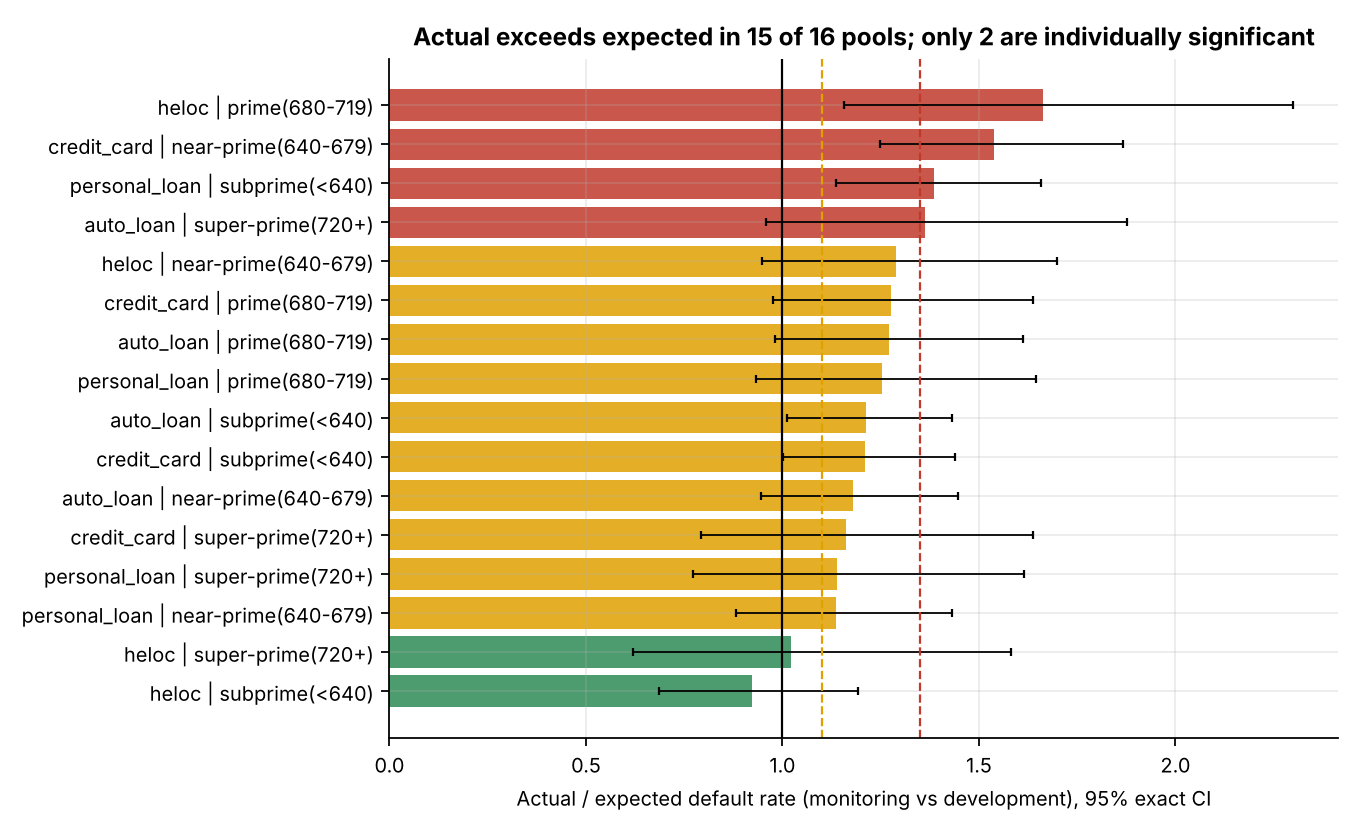

In [4]:
ae = pd.read_csv(TABLES / '02_actual_vs_expected_by_pool.csv'); display(ae[['pool_id','n_mon','rate_dev','rate_mon','AE_ratio','AE_ci_low','AE_ci_high','bonferroni_p','status']])
show_image(FIGS / 'fig04_actual_vs_expected_by_pool.png')

In [5]:
sm = pd.read_csv(TABLES / '02_monitoring_summary.csv').iloc[0]; display(sm.to_frame('value'))

,value
AE_simple_mean_of_pools,1.2512
AE_portfolio_default_rate_ratio,1.2473
AE_dev_truncated_29m_simple_mean,1.2809
AE_horizon_matched_simple_mean,1.5457
AE_horizon_matched_portfolio,1.5603
common_shift_c,1.2462
heterogeneity_chi2,14.0375
heterogeneity_dof,15.0000
heterogeneity_p,0.5227
pools_above_1p10,14.0000


### How to read this honestly
* The signal is real in aggregate: the simple mean of pool A/E is **1.25**, and 14 of 16 pools are above 1.10.
* But **only 2 pools are individually significant** after a Bonferroni correction, and a chi-square test **cannot reject a single common shift** across all pools (p ≈ 0.52). The spread of A/E from 0.92 to 1.66 is what sampling noise looks like in pools of 200 to 1,000 loans.
* Consequence for method: fitting a separate adjustment to each pool would chase noise. That is why the update pools the evidence and keeps the monotonicity constraint, rather than scaling each pool by its own A/E (tested in notebook 03).
* Raw rates ignore that monitoring loans are younger (at most 29 months on book, against 35). Comparing with the **model's own cumulative PD up to each loan's months on book** (horizon-matched A/E) gives **about 1.55**, so the raw 1.25 **understates** the deterioration. A cruder truncation of development defaults at 29 months (1.28) still mixes loans of different ages. This does not change the recalibration, which uses life tables that already handle age; it changes how large a forecast adjustment the allowance committee may need to consider.

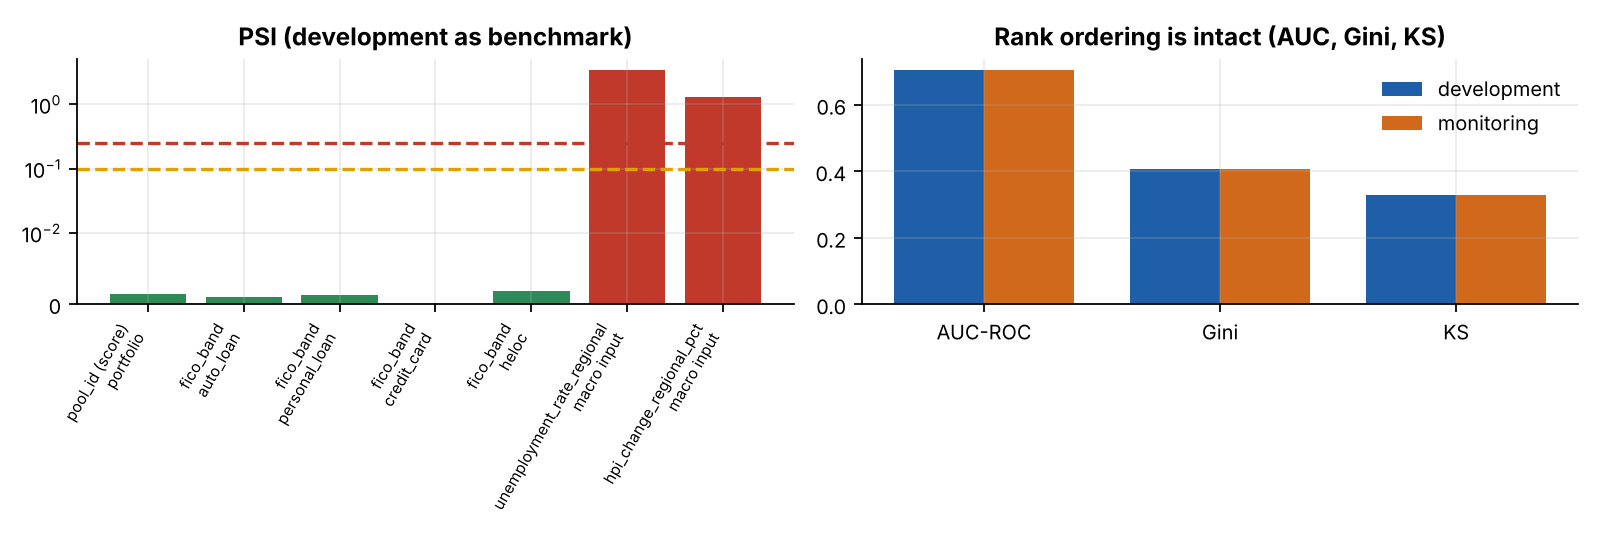

In [6]:
show_image(FIGS / 'fig05_psi_and_discrimination.png')

## 4. Decision
Levels are off (A/E ≈ 1.25), ranking is fine (AUC 0.704 vs 0.704), macro inputs are red. That points to **recalibration of PD** on fresh evidence. It is not a new methodology. Next: classify the change and size it (notebook 03).